<a href="https://colab.research.google.com/github/tithisorker187/Biostatistics-lab/blob/main/DM325.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



# Problem-3



In [ ]:
# Import libraries
import pandas as pd

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, roc_auc_score


In [ ]:
# Generate the same dataset
X, y = make_classification(
    n_samples=500,
    n_features=6,
    n_informative=4,
    n_redundant=1,
    n_classes=2,
    random_state=42
)

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42
)

# Define three classifiers
models = {
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Gaussian Naive Bayes': GaussianNB(),
    'KNN': KNeighborsClassifier(n_neighbors=5)
}

# Store AUC scores
results = []

In [ ]:
#1)Train the model
for name,model in models.items():
    model.fit(X_train,y_train)
    y_prob=model.predict_proba(X_test)[:,1]
    y_pred = model.predict(X_test)

In [ ]:
# 3. Confusion matrix
cm = confusion_matrix(y_test, y_pred)
print("\nModel:", name)
print("Confusion Matrix:")
print(cm)


Model: KNN
Confusion Matrix:
[[63 12]
 [16 59]]


In [ ]:
# 4. ROC-AUC score
auc = roc_auc_score(y_test, y_pred)
print("ROC-AUC Score:", round(auc, 4))
# Store results
results.append({
    'Model': name,
    'AUC': auc
})

ROC-AUC Score: 0.8133


In [ ]:
# 5. Compare models
comparison = pd.DataFrame(results)
comparison = comparison.sort_values(
    by='AUC', ascending=False
).reset_index(drop=True)
print(comparison)

  Model       AUC
0   KNN  0.813333


In [ ]:
best_model = comparison.loc[0]
print("Best Model:", best_model)

Best Model: Model         KNN
AUC      0.813333
Name: 0, dtype: object


# Problem-2
Using Python and scikit-learn, generate a binary classification dataset with 500 observations, 6 features, 4 informative features, 1 redundant feature, 2 classes and random_state = last two digits of your roll number


In [ ]:
from sklearn.datasets import make_classification
import pandas as pd

# Generate binary classification dataset
X, y = make_classification(
    n_samples=500,
    n_features=6,
    n_informative=4,
    n_redundant=1,
    n_classes=2,
    random_state=42
)

# Create DataFrame
df = pd.DataFrame(X, columns=[
    'Feature1', 'Feature2', 'Feature3',
    'Feature4', 'Feature5', 'Feature6'
])

df['Target'] = y

# Display dataset
print(df.head())

# Check dimensions
print("Dataset shape:", df.shape)


   Feature1  Feature2  Feature3  Feature4  Feature5  Feature6  Target
0  0.071408 -1.940913  1.691954  0.086355 -4.181512  2.947127       1
1 -2.077537 -0.626351  0.897010 -0.168507 -0.822142 -1.069852       0
2 -0.461293 -1.476548  0.664429  0.435675  1.306103 -2.354093       0
3 -2.730796 -4.966780  0.711024 -0.836628 -5.170028 -1.949203       1
4  0.863693  0.467695  2.000070  1.669229 -2.864411  4.853752       1
Dataset shape: (500, 7)
Target
0    251
1    249
Name: count, dtype: int64


Perform the following:

1. Display the first five observations.
2. Split the data into 70% training and 30% testing sets.
3. Apply Logistic Regression to the training data.
4. Predict the class labels and probability scores for the test data.
5. Construct the confusion matrix.
6. Plot the ROC curve and calculate the AUC.
7. Briefly interpret the obtained AUC value

In [ ]:
# Import libraries
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score

In [ ]:
# Generate dataset
X, y = make_classification(
    n_samples=500,
    n_features=6,
    n_informative=4,
    n_redundant=1,
    n_classes=2,
    random_state=42
)

# Create DataFrame
df = pd.DataFrame(X, columns=[
    'X1', 'X2', 'X3', 'X4', 'X5', 'X6'
])
df['Target'] = y

# 1. Display first five observations
print("First five observations:")
print(df.head())

# Separate input and target
X = df.drop('Target', axis=1)
y = df['Target']


First five observations:
         X1        X2        X3        X4        X5        X6  Target
0  0.071408 -1.940913  1.691954  0.086355 -4.181512  2.947127       1
1 -2.077537 -0.626351  0.897010 -0.168507 -0.822142 -1.069852       0
2 -0.461293 -1.476548  0.664429  0.435675  1.306103 -2.354093       0
3 -2.730796 -4.966780  0.711024 -0.836628 -5.170028 -1.949203       1
4  0.863693  0.467695  2.000070  1.669229 -2.864411  4.853752       1


In [ ]:
# 2. Split data: 70% training, 30% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42
)

print("Training size:", X_train.shape[0])
print("Testing size:", X_test.shape[0])

Training size: 350
Testing size: 150


In [ ]:
# 3. Apply Logistic Regression
model = LogisticRegression()
model.fit(X_train, y_train)

LogisticRegression()

In [ ]:
# 4. Predict class labels and probabilities
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Predicted class labels:")
print(y_pred)

print("Predicted probabilities for class 1:")
print(y_prob)

Predicted class labels:
[1 1 0 0 0 1 1 1 1 1 1 0 1 1 0 0 1 1 0 1 0 1 0 0 0 0 1 0 1 0 0 1 0 0 0 1 1
 1 1 1 0 1 1 1 1 0 1 1 0 0 1 1 1 0 1 1 1 1 0 0 0 0 1 0 1 0 1 0 0 0 1 0 1 0
 0 0 1 0 1 1 1 0 1 1 0 0 1 1 1 1 1 1 0 1 0 1 0 0 1 0 1 1 0 1 0 1 0 0 0 1 1
 0 0 1 1 1 0 0 0 1 0 0 0 0 0 0 1 0 0 0 0 1 0 0 1 1 1 1 0 1 1 0 0 1 0 0 0 1
 1 1]
Predicted probabilities for class 1:
[0.68439264 0.78977917 0.33748956 0.16363877 0.36722651 0.52859105
 0.63391566 0.73116542 0.58653416 0.6402683  0.58260871 0.15966469
 0.70026291 0.70082749 0.2822824  0.22541228 0.82205704 0.64087416
 0.45197096 0.91127947 0.20751199 0.51700993 0.38371557 0.41852241
 0.46086086 0.43799267 0.58709212 0.41650655 0.68721452 0.35684679
 0.23681032 0.51709288 0.21789378 0.45466957 0.30259343 0.59332797
 0.80621865 0.60476703 0.75859646 0.82835176 0.22815222 0.77964305
 0.50433462 0.55775701 0.70441193 0.23301734 0.70000046 0.60833706
 0.0742626  0.228235   0.79909755 0.57913172 0.64690168 0.14690683
 0.60347929 0.87149775 0.54225

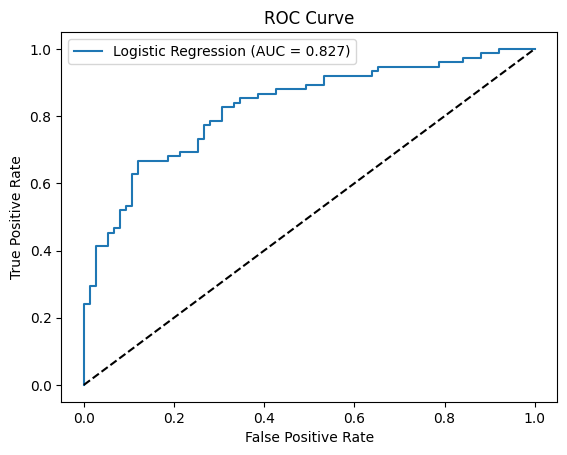

AUC: 0.8270222222222222


In [ ]:
# 6. Plot ROC curve and calculate AUC
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

plt.plot(fpr, tpr, label='Logistic Regression (AUC = %.3f)' % auc)
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

print("AUC:", auc)

AUC = 1.0: Perfect classification.
AUC = 0.8–0.9: Good classification performance.
AUC = 0.7–0.8: Acceptable discrimination.
AUC = 0.5: No discrimination; equivalent to random ranking.

# Problem-4

In [ ]:
# Import libraries
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

In [ ]:
# Generate 2D dataset
X, y_true = make_blobs(
    n_samples=300,
    centers=3,
    n_features=2,
    random_state=42
)

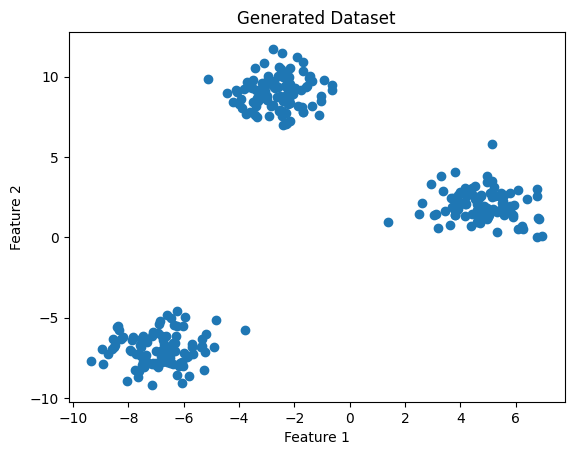

In [ ]:
# 1) Plot generated observations
plt.scatter(X[:, 0], X[:, 1])
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Generated Dataset')
plt.show()

In [ ]:
# 2. Apply K-Means with 3 clusters
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

y_pred = kmeans.fit_predict(X)


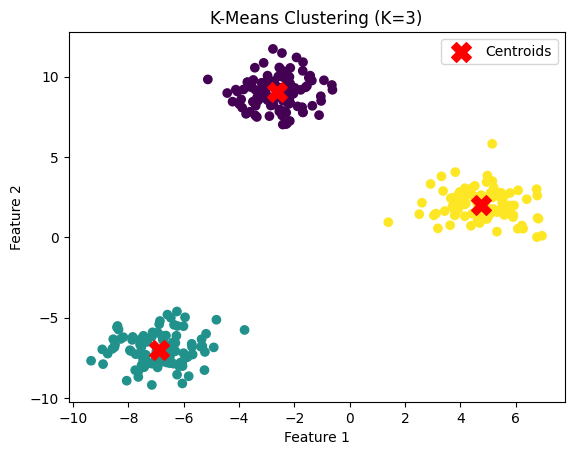

In [ ]:
# 3. Plot resulting clusters and centroids
plt.scatter(X[:, 0], X[:, 1], c=y_pred, cmap='viridis')

centroids = kmeans.cluster_centers_

plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    marker='X',
    s=200,
    color='red',
    label='Centroids'
)

plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('K-Means Clustering (K=3)')
plt.legend()
plt.show()

In [ ]:
# 4. Calculate Adjusted Rand Index
ari = adjusted_rand_score(y_true, y_pred)

print("Adjusted Rand Index (ARI):", round(ari, 4))

Adjusted Rand Index (ARI): 1.0


Interpretation of ARI
The Adjusted Rand Index compares the predicted clusters with the true cluster labels, accounting for agreement expected by chance.
ARI = 1: Perfect clustering agreement.
ARI ≈ 0: Agreement similar to random clustering.
ARI < 0: Agreement worse than expected by chance.
Conclusion: A high ARI indicates that K-Means successfully recovered the original clusters. The exact ARI value will be displayed by your code. Since the data are generated from three blobs, K-Means will often achieve a high ARI when the clusters are well separated.